# Plot cutflows

In [15]:
import warnings
warnings.filterwarnings("ignore", message="numpy.dtype size changed")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
pd.option_context('display.max_columns', -1)

# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.3)
cm = plt.colormaps['RdYlBu']

In [16]:
def closestRow(df, point, relative=True):
    """Return a one-row DataFrame with the row of df closest to point 
    (dict column -> value)."""
    cols = list(point.keys())
    target = pd.Series(point)
    diff = df[cols] - target
    if relative:
        diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
    dist = (diff**2).sum(axis=1)
    return df.loc[[dist.idxmin()]]   # double brackets keep it a DataFrame


## Load CutFlows

In [9]:
b2tfCutFlows_DF = pd.read_csv('../b2tf_cutFlows.csv')
b2tfCutFlows_DF['dm'] = (b2tfCutFlows_DF['m1']-b2tfCutFlows_DF['m0']).round(0)
b2tfCutFlows_DF['ctau'] = (b2tfCutFlows_DF['tau']*2.99e8).round(0)
b2tfCutFlows_DF['eff'] = b2tfCutFlows_DF['(n+1): nroi >= 3']/b2tfCutFlows_DF['all']


### Plot cutflow

In [23]:
cf_labels = {
    'all': 'Total',
    'l1(n): 200 gev < met(n)': r'L1: $E_T^{\rm miss} > 200$ GeV',
    'l1(n): 150 gev < ptj1(n)': r'L1: $p_T^{j_1} > 150$ GeV',
    '(n+1): 25 ns < t < 50 ns': r'25 ns $ < t < 50$ ns',
    '(n+1): decay in ms': 'Decay in MS',
    '(n+1): nroi >= 3': r'$n_{\rm RoI} \geq 3$',
}


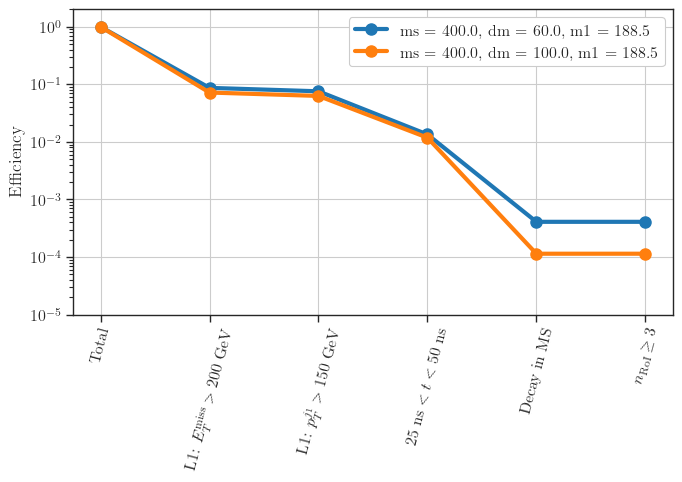

In [ ]:
fig = plt.figure(figsize=(7,5))

selectPoints = [{'ms' : 400.0, 'dm' : 60.0, 'm1' : 189.0},  {'ms' : 400.0, 'dm' : 100.0, 'm1' : 189.0}]

for pt in selectPoints:
    data = closestRow(b2tfCutFlows_DF, pt)
    label = ', '.join([f'{key} = {data[key].iloc[0]}' for key in pt])
    x_ticks = list(cf_labels.keys())
    x_ticksL = [cf_labels.get(c, c) for c in x_ticks]
    x = np.arange(0.,len(x_ticksL),1.)
    plt.xticks(x, x_ticksL,rotation=75)
    y = data.iloc[0][x_ticks]/data.iloc[0]['all']
    p = plt.plot(x,y,label=label,linewidth=3,marker='o',markersize=8)
plt.yscale('log')
plt.ylabel('Efficiency')
plt.ylim(1e-5,2.0)
# plt.yticks([1e-5,1e-4,1e-3,1e-2,1e-1,1.])
plt.legend(framealpha=1.0)    
plt.grid()
plt.tight_layout()
plt.show()

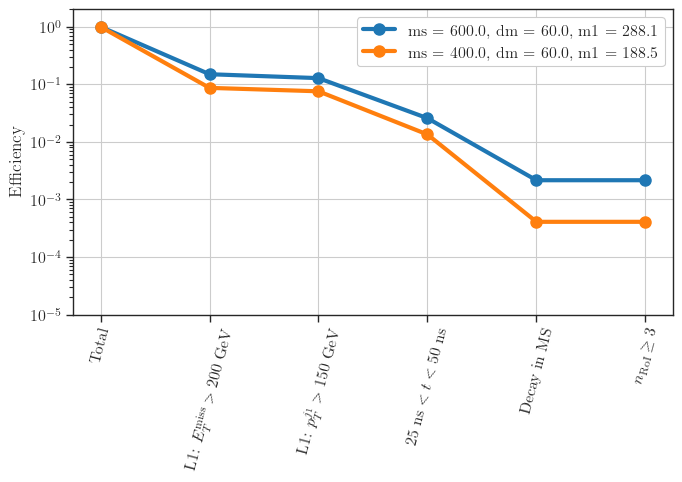

In [28]:
fig = plt.figure(figsize=(7,5))

selectPoints = [{'ms' : 600.0, 'dm' : 60.0, 'm1' : 289.0},  {'ms' : 400.0, 'dm' : 60.0, 'm1' : 189.0}]

for pt in selectPoints:
    data = closestRow(b2tfCutFlows_DF, pt)
    label = ', '.join([f'{key} = {data[key].iloc[0]}' for key in pt])
    x_ticks = list(cf_labels.keys())
    x_ticksL = [cf_labels.get(c, c) for c in x_ticks]
    x = np.arange(0.,len(x_ticksL),1.)
    plt.xticks(x, x_ticksL,rotation=75)
    y = data.iloc[0][x_ticks]/data.iloc[0]['all']
    p = plt.plot(x,y,label=label,linewidth=3,marker='o',markersize=8)
plt.yscale('log')
plt.ylabel('Efficiency')
plt.ylim(1e-5,2.0)
# plt.yticks([1e-5,1e-4,1e-3,1e-2,1e-1,1.])
plt.legend(framealpha=1.0)    
plt.grid()
plt.tight_layout()
plt.show()